<a href="https://colab.research.google.com/github/Jeffrey-Huber/COPD-Project/blob/main/Project_Huber_Jeffrey.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **STAT 200 Project**

#### **WRITE YOUR NAME HERE**


---

<br>

For your project, you must analyze data from the [COPDGene study](http://www.copdgene.org/) using the concepts covered in this course. Please follow the directions below carefully:

- <font color=red>Tasks</font> indicated in red must be completed to receive credit
- Include all code for your work
- Comment all code using the `#`. This is a must!
- Include markdown cells with written answers explaining your work when prompted
- **NOTE: Your completed project must be submitted to Canvas as a .ipynb file by the assigned due date**



<br>

---

<br>






## Data

Data for the project is available from three separate data sources.
  * [demographics data](https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_demographics.csv)
  * [medical image data](https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_imaging.json)
  * [spirometry data](https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_spirometry.html)
  
A data dictionary describing the meaning of each of the variables in the dataset is available [here](https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_dictionary.csv).

<br>

---

<br>






## Introduction

Chronic obstructive pulmonary disease (COPD) affects over 16 million Americans and is the fourth leading cause of death in the United States behind heart disease, cancer, and accidental death. While COPD can result from various toxic inhalations or asthma, it is most commonly associated with cigarette smoking.

<br>

COPD severity is typically measured by a device called a spirometer. Patients forcefully exhale into the device and the volume of air exhaled is used as a measure for the severity of disease (less air exhaled $\Rightarrow$ worse disease). Data collected by the COPDGene research group includes spirometry data on thousands of research participants.

<br>

Spirometry measures in the dataset:
* The forced expiratory volume (FEV1) is the volume of air exhaled in 1 second
* The forced vital capacity (FVC) is the total volume of air exhaled after a full breath
* FEV1_FVC_ratio is the ratio between FEV1 and FVC (smaller $\Rightarrow$ worse disease)
* FEV1_phase2 is the FEV1 of research participants 5 years later

<br>

You overall task in this project is to analyze the relationship between FEV1 at follow-up (FEV1_phase2) and other variables in the dataset. The project has been organized into a series of tasks to assist you with your analysis organization.

<br>

---

<br>






####<font color=red>Organized</font>
* Answers should be organized in the following format for organization and readability

<br>

```
# 1.
This will be the code block to answer the first part of a task
```

1. This will be the text answer/explanation (if prompted) for the first task

```
# 2.
This will be the code block to answer the second part of a task in a separate code cell
```

2. This will be the text answer/explanation (if prompted) for the second task

<br>

Continue this format for the remaining subtasks


<br>

<br>

---






## Data Wrangling

####<font color=red>Task 1</font>

Using code covered in the course,

1. Load the COPDGene demographics dataset.

2. Load the COPDGene medical image dataset as a data frame. You must process the data to ensure the data is stored as a data frame.

3. Load the COPDGene spirometry dataset as a data frame. You must process the data to ensure the data is stored as a data frame.

In [ ]:
#1

library(jsonlite)
library(rvest)

geneDemo  <- read.csv("https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_demographics.csv")

geneImg   <- fromJSON("https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_imaging.json")

geneUrl   <- read_html("https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_spirometry.html")

geneTable <- html_table(geneUrl)

geneSpir  <- geneTable[[1]]

head(geneSpir)

head(geneImg)

head(geneDemo)

sid,fev1_fvc_ratio,fev1,fvc,fev1_phase2
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
22035P,0.62,3.672,5.954,3.484
25109H,0.81,1.968,2.432,2.049
10127E,0.83,2.319,2.788,2.133
15450K,0.51,2.398,4.745,1.424
13689J,0.75,3.938,5.273,3.571
15749L,0.81,2.784,3.446,2.309


,sid,lung_volume_inspiratory,emphysema_percentage,lung_volume_expiratory,gas_trapping_percentage,mean_density_inspiratory,mean_density_expiratory
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,24838L,4.1956,1.3740,2.2976,10.5587,-829.631,-684.559
2,14901M,5.7800,3.7793,2.9900,11.6639,-836.006,-674.285
3,11357A,5.4958,4.7153,2.7493,16.9214,-855.705,-727.824
4,20152J,4.9409,8.4237,3.2121,39.4071,-850.767,-777.023
5,21437E,4.6451,0.0600,2.9805,2.6216,-762.127,-656.432
6,15807Z,5.6987,2.1956,3.0119,12.5120,-844.875,-710.280


,sid,visit_year,visit_date,visit_age,gender,race,smoking_status,height_cm,weight_kg,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,hours_on_oxygen,bmi,smoke_start_age,cigs_per_day_avg,duration_smoking,respiratory
,<chr>,<int>,<chr>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>
1,10005Q,2008,1/15/2008,54.5,2,1,2,159.9,73.0,130,80,87,0,28.55,14,20,40.5,
2,10055F,2008,3/15/2008,69.0,1,2,1,178.0,90.7,168,100,55,0,28.63,18,20,20.0,hay fever
3,10056H,2008,2/15/2008,48.7,2,1,1,153.7,86.2,100,53,98,24,36.49,12,40,36.0,asthma|bronchitis attacks|chronic bronchitis|pneumonia|emphysema|copd|sleep apnea
4,10060Y,2008,5/15/2008,72.8,1,1,1,177.0,89.6,147,71,87,24,28.60,17,30,54.0,asthma|bronchitis attacks|chronic bronchitis|emphysema|copd
5,10068O,2008,3/15/2008,76.2,2,1,1,155.0,55.0,134,78,92,0,22.89,18,20,52.0,hay fever|bronchitis attacks|chronic bronchitis|pneumonia|emphysema|copd
6,10072F,2008,3/15/2008,70.0,2,1,1,165.1,76.1,92,58,77,12,27.92,16,40,48.0,pneumonia|emphysema|copd


<br>

<br>


---






####<font color=red>Task 2</font>

Using code covered in the course,

1. Merge the demographics, medical imaging, and spirometry datasets by the anonymized ID into a single dataset. Be sure to keep all rows from all datasets.

  Hint: You should have 2,620 observations after the merge.

In [ ]:
#2

temp   <- merge(x     = geneDemo,
                y     = geneImg,
                by.x  = "sid",
                by.y  = "sid",
                all.x = TRUE,
                all.y = TRUE)

geneDf <- merge(x     = temp,
                y     = geneSpir,
                by.x  = "sid",
                by.y  = "sid",
                all.x = TRUE,
                all.y = TRUE)
str(geneDf)

'data.frame':	2620 obs. of  28 variables:
 $ sid                     : chr  "10005Q" "10055F" "10056H" "10060Y" ...
 $ visit_year              : int  2008 2008 2008 2008 2008 2008 2008 2008 2008 2008 ...
 $ visit_date              : chr  "1/15/2008" "3/15/2008" "2/15/2008" "5/15/2008" ...
 $ visit_age               : num  54.5 69 48.7 72.8 76.2 70 61.8 69.6 47.8 71.5 ...
 $ gender                  : int  2 1 2 1 2 2 1 2 1 1 ...
 $ race                    : int  1 2 1 1 1 1 1 1 1 1 ...
 $ smoking_status          : int  2 1 1 1 1 1 1 1 2 1 ...
 $ height_cm               : num  160 178 154 177 155 ...
 $ weight_kg               : num  73 90.7 86.2 89.6 55 ...
 $ blood_pressure_systolic : int  130 168 100 147 134 92 108 144 139 140 ...
 $ blood_pressure_diastolic: int  80 100 53 71 78 58 78 90 90 75 ...
 $ heart_rate              : int  87 55 98 87 92 77 72 110 87 73 ...
 $ hours_on_oxygen         : int  0 0 24 24 0 12 0 0 0 24 ...
 $ bmi                     : num  28.6 28.6 36.5 28.6 22.9

<br>

<br>

<br>

---

<br>






####<font color=red>Task 3</font>

Using code covered in the course,

1. Convert the variables `gender`, `race`, and `smoking_status` to factors

2. Reassign the levels appropriately. Hint: See data dictionary.

In [ ]:
#3

geneDf$gender                 <- as.factor(geneDf$gender)
geneDf$race                   <- as.factor(geneDf$race)
geneDf$smoking_status         <- as.factor(geneDf$smoking_status)

levels(geneDf$gender)         <- c("Male", "Female")
levels(geneDf$race)           <- c("White", "Black")
levels(geneDf$smoking_status) <- c("Never Smoked", "Former Smoker", "Current Smoker")

head(geneDf)

,sid,visit_year,visit_date,visit_age,gender,race,smoking_status,height_cm,weight_kg,blood_pressure_systolic,⋯,lung_volume_inspiratory,emphysema_percentage,lung_volume_expiratory,gas_trapping_percentage,mean_density_inspiratory,mean_density_expiratory,fev1_fvc_ratio,fev1,fvc,fev1_phase2
,<chr>,<int>,<chr>,<dbl>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,10005Q,2008,1/15/2008,54.5,Female,White,Former Smoker,159.9,73.0,130,⋯,5.6636,0.9269,2.4766,6.8008,-830.343,-650.526,0.77,2.921,3.805,2.622
2,10055F,2008,3/15/2008,69.0,Male,Black,Never Smoked,178.0,90.7,168,⋯,4.9060,1.9452,1.9057,10.6835,-823.746,-638.442,0.73,2.917,3.999,2.439
3,10056H,2008,2/15/2008,48.7,Female,White,Never Smoked,153.7,86.2,100,⋯,4.8654,11.3832,4.0606,47.8811,-836.281,-797.471,0.29,0.374,1.281,0.379
4,10060Y,2008,5/15/2008,72.8,Male,White,Never Smoked,177.0,89.6,147,⋯,7.3304,19.2623,5.3342,53.4747,-867.254,-821.256,0.29,0.706,2.424,1.405
5,10068O,2008,3/15/2008,76.2,Female,White,Never Smoked,155.0,55.0,134,⋯,6.0099,41.7757,4.1552,66.1621,-903.436,-856.337,0.46,0.806,1.736,0.580
6,10072F,2008,3/15/2008,70.0,Female,White,Never Smoked,165.1,76.1,92,⋯,3.9788,2.4735,2.8876,31.0631,-816.235,-747.113,0.57,1.573,2.752,1.477


<br>

<br>

<br>

---

<br>






####<font color=red>Task 4</font>

Using code covered in the course,

1. Convert heights to inches and weight to pounds

In [ ]:
#4
height_in         <- geneDf$height_cm / 2.54
weight_lbs        <- geneDf$weight_kg * 2.2

geneDf$height_in  <- height_in
geneDf$weight_lbs <- weight_lbs




head(geneDf)

,sid,visit_year,visit_date,visit_age,gender,race,smoking_status,height_cm,weight_kg,blood_pressure_systolic,⋯,lung_volume_expiratory,gas_trapping_percentage,mean_density_inspiratory,mean_density_expiratory,fev1_fvc_ratio,fev1,fvc,fev1_phase2,height_in,weight_lbs
,<chr>,<int>,<chr>,<dbl>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,10005Q,2008,1/15/2008,54.5,Female,White,Former Smoker,159.9,73.0,130,⋯,2.4766,6.8008,-830.343,-650.526,0.77,2.921,3.805,2.622,62.95276,160.60
2,10055F,2008,3/15/2008,69.0,Male,Black,Never Smoked,178.0,90.7,168,⋯,1.9057,10.6835,-823.746,-638.442,0.73,2.917,3.999,2.439,70.07874,199.54
3,10056H,2008,2/15/2008,48.7,Female,White,Never Smoked,153.7,86.2,100,⋯,4.0606,47.8811,-836.281,-797.471,0.29,0.374,1.281,0.379,60.51181,189.64
4,10060Y,2008,5/15/2008,72.8,Male,White,Never Smoked,177.0,89.6,147,⋯,5.3342,53.4747,-867.254,-821.256,0.29,0.706,2.424,1.405,69.68504,197.12
5,10068O,2008,3/15/2008,76.2,Female,White,Never Smoked,155.0,55.0,134,⋯,4.1552,66.1621,-903.436,-856.337,0.46,0.806,1.736,0.580,61.02362,121.00
6,10072F,2008,3/15/2008,70.0,Female,White,Never Smoked,165.1,76.1,92,⋯,2.8876,31.0631,-816.235,-747.113,0.57,1.573,2.752,1.477,65.00000,167.42


<br>

<br>

<br>

---

<br>






####<font color=red>Task 5</font>

Using code on ***text processing*** covered in the course,

1. Convert the `respiratory` variable into eight separate variables

  * `hay_fever` - `"Yes"` or `"No"`
  * `asthma` - `"Yes"` or `"No"`
  * `bronchitis_attacks` - `"Yes"` or `"No"`
  * `chronic_bronchitis` - `"Yes"` or `"No"`
  * `pneumonia` - `"Yes"` or `"No"`
  * `emphysema` - `"Yes"` or `"No"`
  * `copd` - `"Yes"` or `"No"`
  * `sleep_apnea` - `"Yes"` or `"No"`

In [ ]:
#5
split_cols                          <- strsplit(geneDf$respiratory, "\\|")
all_diseases                        <- unique(unlist(split_cols))
diseases_cols                       <- matrix("no", nrow = nrow(geneDf), ncol = length(all_diseases))
colnames(diseases_cols)             <- all_diseases
for(i in seq_along(split_cols)){
  diseases_cols[i, split_cols[[i]]] <- "yes"
}

diseases_cols_final <- data.frame(sid = geneDf$sid, diseases_cols)

geneDf <- merge(x     = geneDf,
                y     = diseases_cols_final,
                by.x  = "sid",
                by.y  = "sid",
                all.x = TRUE,
                all.y = FALSE)

head(geneDf)

,sid,visit_year,visit_date,visit_age,gender,race,smoking_status,height_cm,weight_kg,blood_pressure_systolic,⋯,height_in,weight_lbs,hay.fever,asthma,bronchitis.attacks,chronic.bronchitis,pneumonia,emphysema,copd,sleep.apnea
,<chr>,<int>,<chr>,<dbl>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,10005Q,2008,1/15/2008,54.5,Female,White,Former Smoker,159.9,73.0,130,⋯,62.95276,160.60,no,no,no,no,no,no,no,no
2,10055F,2008,3/15/2008,69.0,Male,Black,Never Smoked,178.0,90.7,168,⋯,70.07874,199.54,yes,no,no,no,no,no,no,no
3,10056H,2008,2/15/2008,48.7,Female,White,Never Smoked,153.7,86.2,100,⋯,60.51181,189.64,no,yes,yes,yes,yes,yes,yes,yes
4,10060Y,2008,5/15/2008,72.8,Male,White,Never Smoked,177.0,89.6,147,⋯,69.68504,197.12,no,yes,yes,yes,no,yes,yes,no
5,10068O,2008,3/15/2008,76.2,Female,White,Never Smoked,155.0,55.0,134,⋯,61.02362,121.00,yes,no,yes,yes,yes,yes,yes,no
6,10072F,2008,3/15/2008,70.0,Female,White,Never Smoked,165.1,76.1,92,⋯,65.00000,167.42,no,no,no,no,yes,yes,yes,no


<br>

<br>

<br>

---

<br>






####<font color=red>Task 6</font>

Using code covered in the course,

1. Convert any other variables to their appropriate data structure for analysis

In [ ]:
#6
geneDf$hay.fever          <- as.factor(geneDf$hay.fever)
geneDf$asthma             <- as.factor(geneDf$asthma)
geneDf$bronchitis.attacks <- as.factor(geneDf$bronchitis.attacks)
geneDf$chronic.bronchitis <- as.factor(geneDf$chronic.bronchitis)
geneDf$pneumonia          <- as.factor(geneDf$pneumonia)
geneDf$emphysema          <- as.factor(geneDf$emphysema)
geneDf$copd               <- as.factor(geneDf$copd)
geneDf$sleep.apnea        <- as.factor(geneDf$sleep.apnea)

<br>

<br>

<br>

---

<br>






####<font color=red>Task 7</font>

Using code covered in the course,

1. Remove the `height_cm`, `height_kg`, and `respiratory` columns

2. Export your data as a `.csv` file.

2. Be sure to include this "clean" `.csv` file in your submission as file called `copd_data.csv`

In [ ]:
#7
finalDf <- geneDf[ , !(names(geneDf) %in% c("height_cm", "weight_kg", "respiratory"))]


write.csv(x         = finalDf,
          file      = "copd_data.csv",
          row.names = FALSE)

<br>

<br>

---






## Descriptive Statistics and Exploratory Analysis

####<font color=red>Task 8</font>

Using code covered in the course,

1. Create a function with the following attributes:

  * Takes a single variable/column from your Task 7 data frame as input
  * If the variable is
    * numeric or integer, returns the mean and standard deviation
    * character or factor, returns the frequency (count) of each unique level

In [ ]:
#8
myFunction <- function(my_vector) {
  if (class(my_vector) == "numeric" || class(my_vector) == "integer"){
    vector_mean <- mean(my_vector)
    vector_sd <- sd(my_vector)
    return(list(mean = vector_mean, sd = vector_sd))
  }
  else if(class(my_vector) == "factor" || class(my_vector) == "character"){
    return(table(my_vector))
    }
}

myFunction(finalDf$smoking_status)


my_vector
  Never Smoked  Former Smoker Current Smoker 
          1411           1209              0 

<br>

<br>

<br>

---

<br>






####<font color=red>Task 9</font>

Using code covered in the course,
  
1. Apply your function from Task 8 to each column of the data frame using a ***loop***

  Hint: You can use either a `for` loop or one of the functions from the apply family

2. What are your observations? Do you observe `NA`s? If so, remove those rows before proceeding with your analysis

In [ ]:
#9
analysisDf <- finalDf[ , !(names(finalDf) %in% c("lung_volume_inspiratory", "emphysema_percentage", "lung_volume_expiratory", "gas_trapping_percentage", "mean_density_inspiratory", "mean_density_expiratory", "fev1_fvc_ratio", "fev1", "fvc"))]

for(i in 2:ncol(analysisDf)){
  print(names(analysisDf)[i])
  print(myFunction(analysisDf[, i]))
}

[1] "visit_year"
$mean
[1] 2009.139

$sd
[1] 0.7806731

[1] "visit_date"
my_vector
 1/15/2008  1/15/2009  1/15/2010  1/15/2011 10/15/2008 10/15/2009 10/15/2010 
         1         90         94         21         85        110         40 
11/15/2008 11/15/2009 11/15/2010 12/15/2008 12/15/2009 12/15/2010  2/15/2008 
        50         95         58         61         79         38          1 
 2/15/2009  2/15/2010  2/15/2011  3/15/2008  3/15/2009  3/15/2010  3/15/2011 
       103         77         19         10        109         96         20 
 4/15/2008  4/15/2009  4/15/2010  4/15/2011  5/15/2008  5/15/2009  5/15/2010 
        38        102         78         11         45         90         78 
 6/15/2008  6/15/2009  6/15/2010  7/15/2008  7/15/2009  7/15/2010  8/15/2008 
        48        114         72         77         92         52         76 
 8/15/2009  8/15/2010  9/15/2008  9/15/2009  9/15/2010 
        93         62         78        109         48 
[1] "visit_age"
$mean
[1]

9

Yes there were NAs and I did remove them :) smile

<br>

<br>

<br>

---

<br>






####<font color=red>Task 10</font>

Using `ggplot` code covered in the course,
  
1. Plot a histogram of each of the numeric and integer variables in your data frame. Note that a loop would make this easier!

2. Are there any variables that are highly skewed? If so, transform these variables using an appropriate transformation.

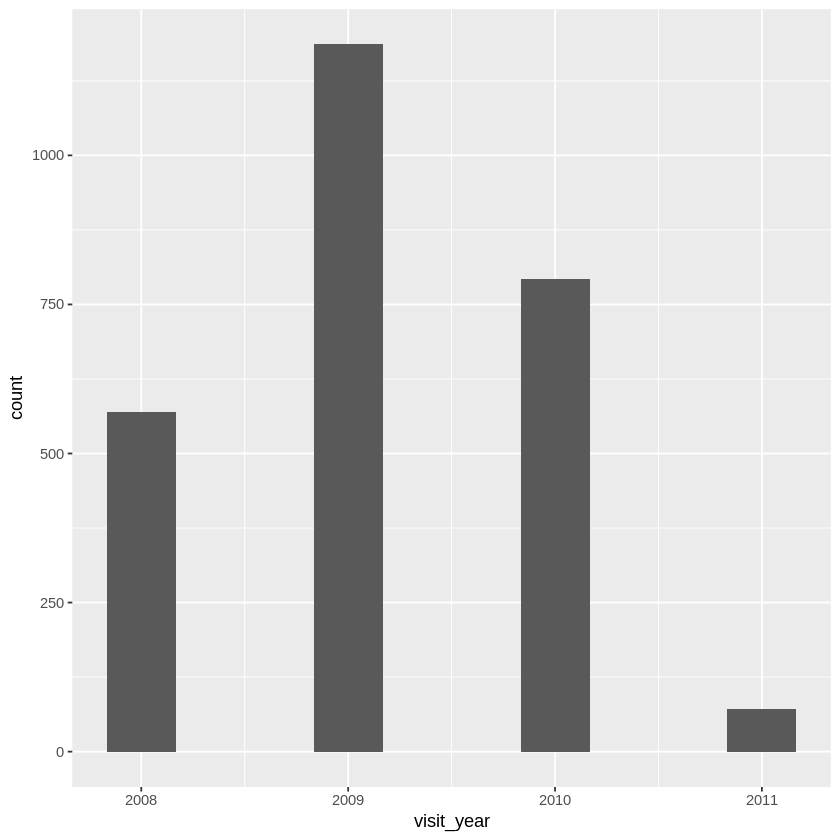

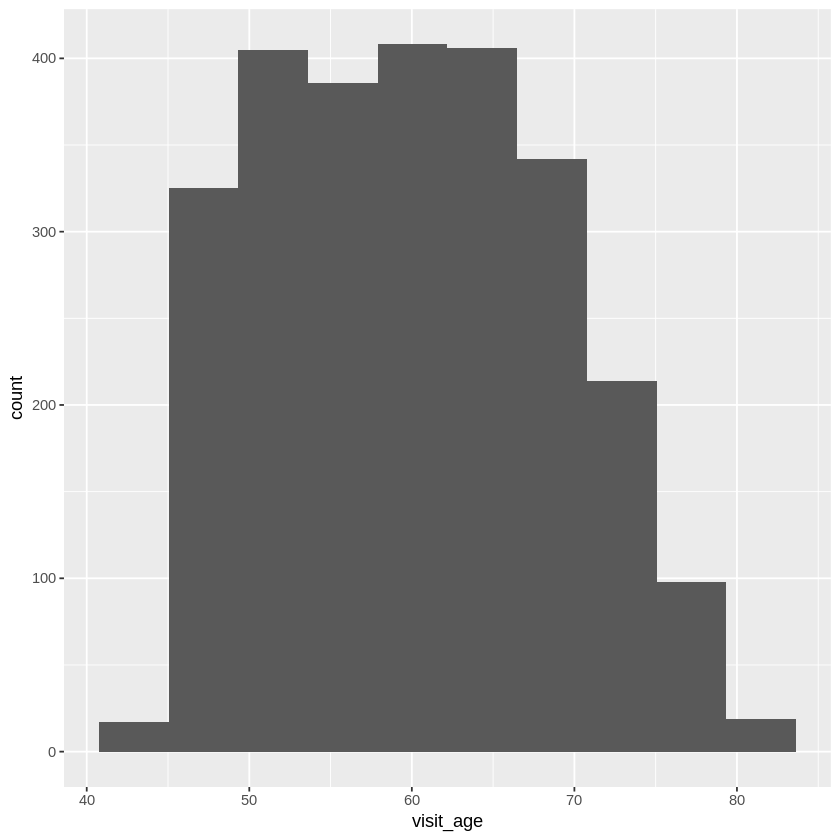

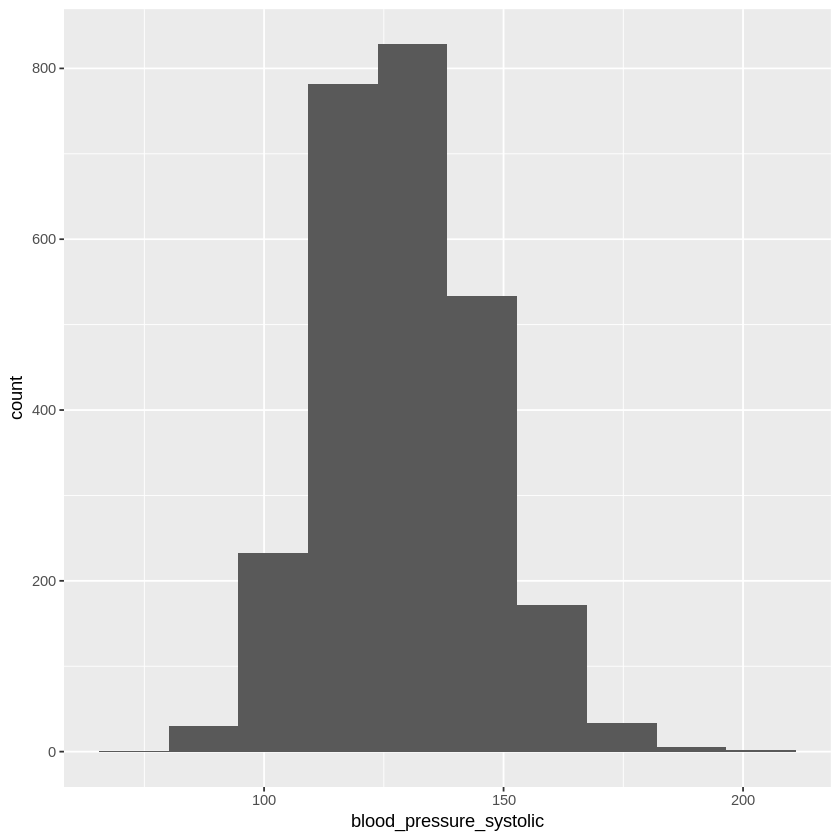

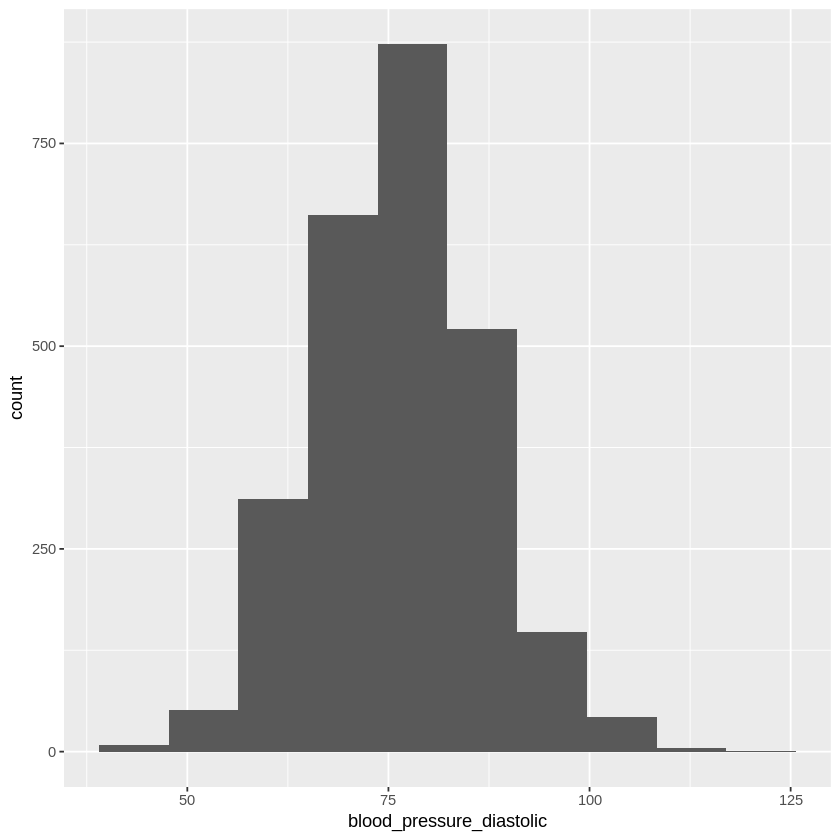

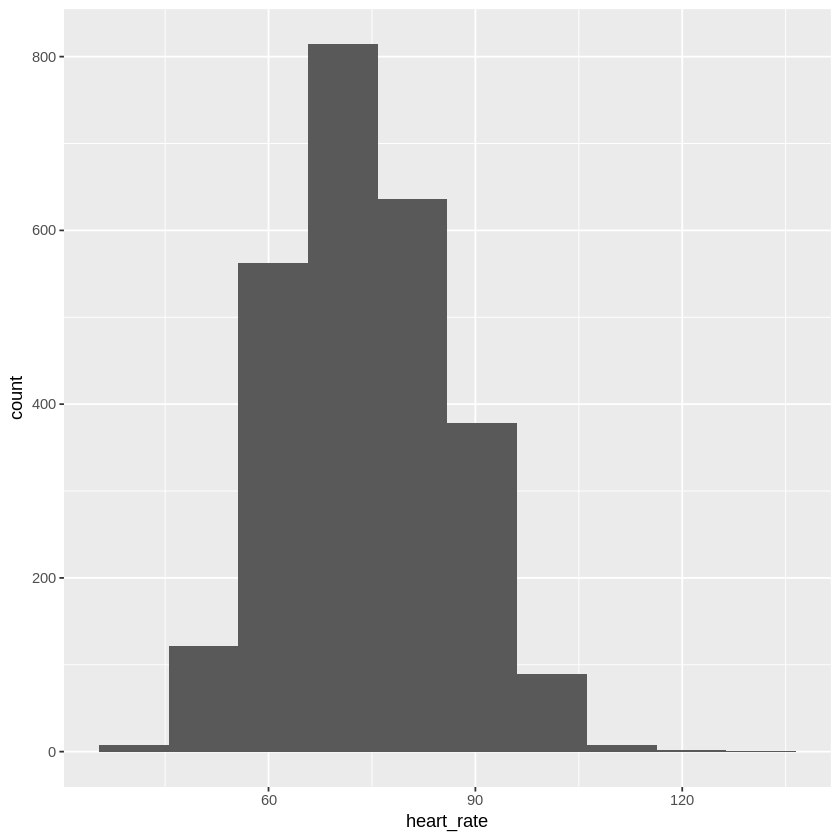

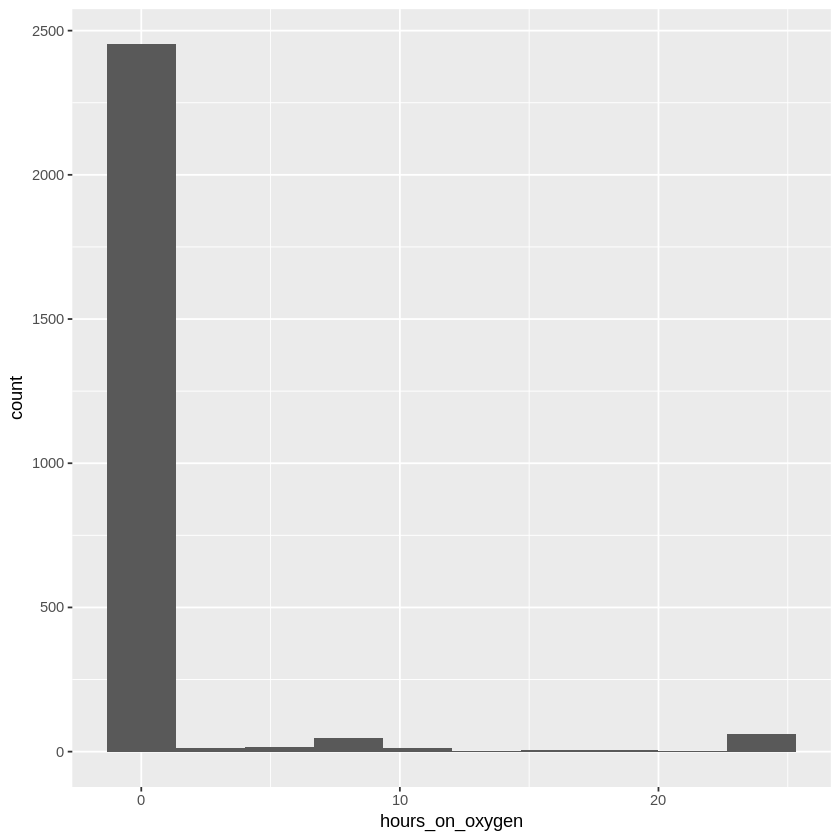

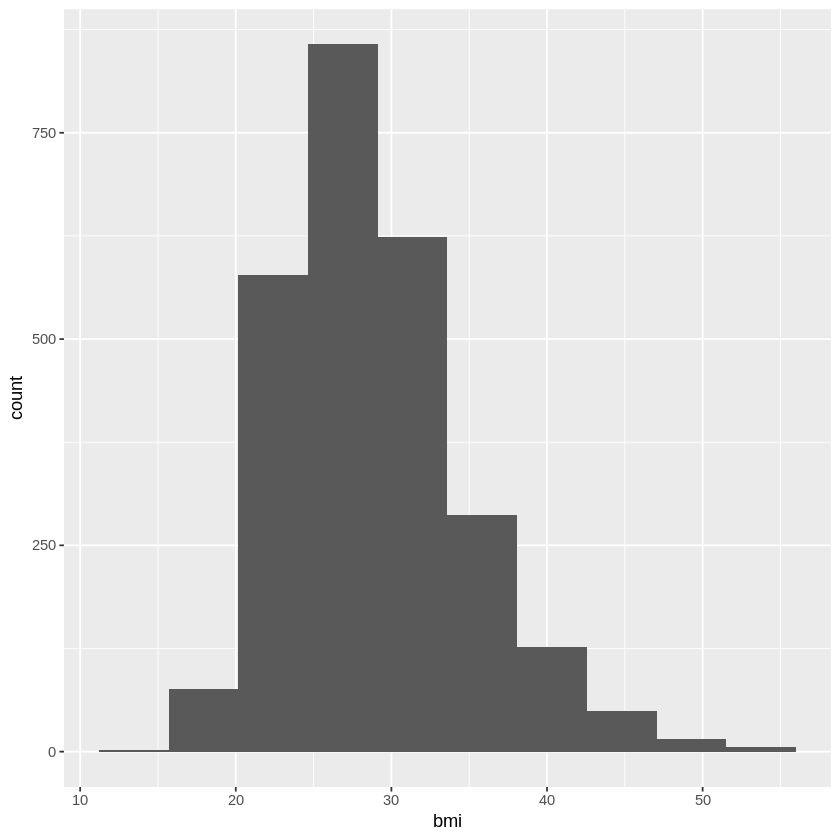

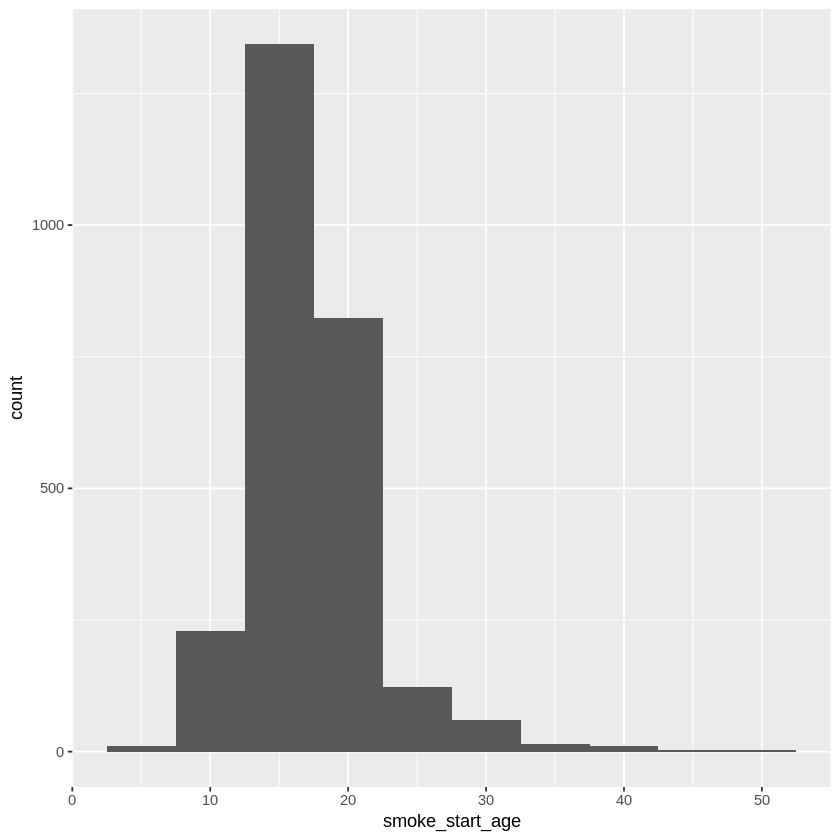

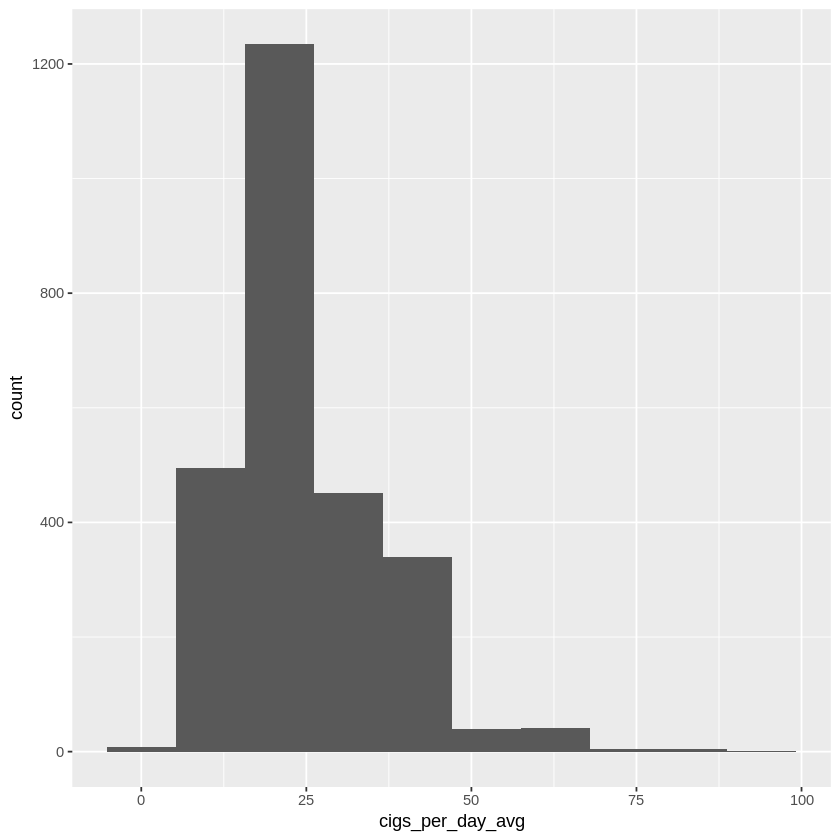

Warning message:
“Removed 10 rows containing non-finite outside the scale range (`stat_bin()`).”


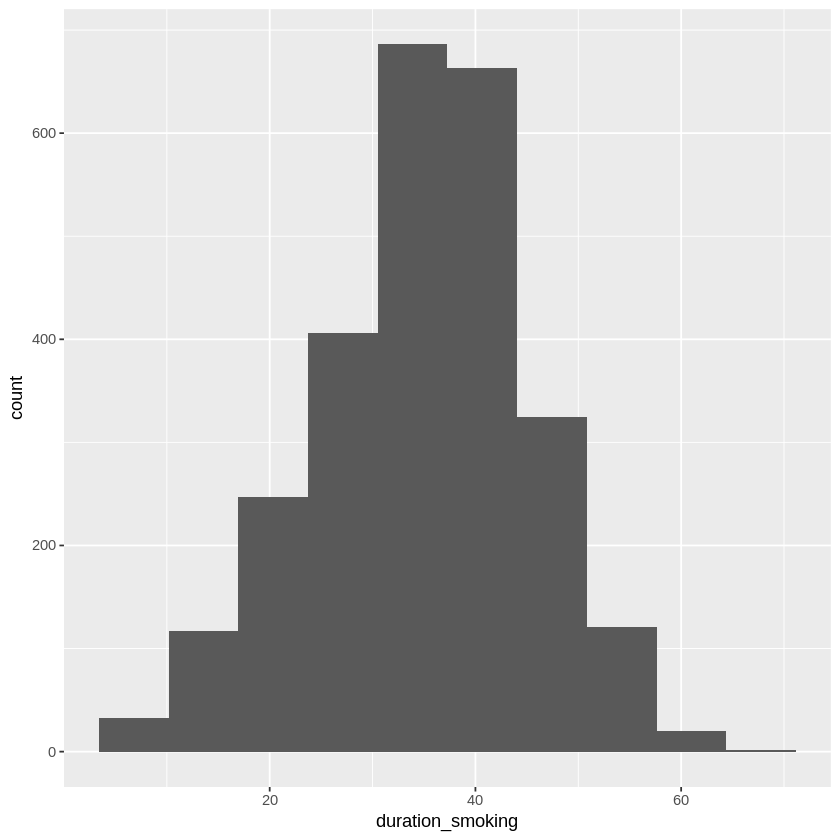

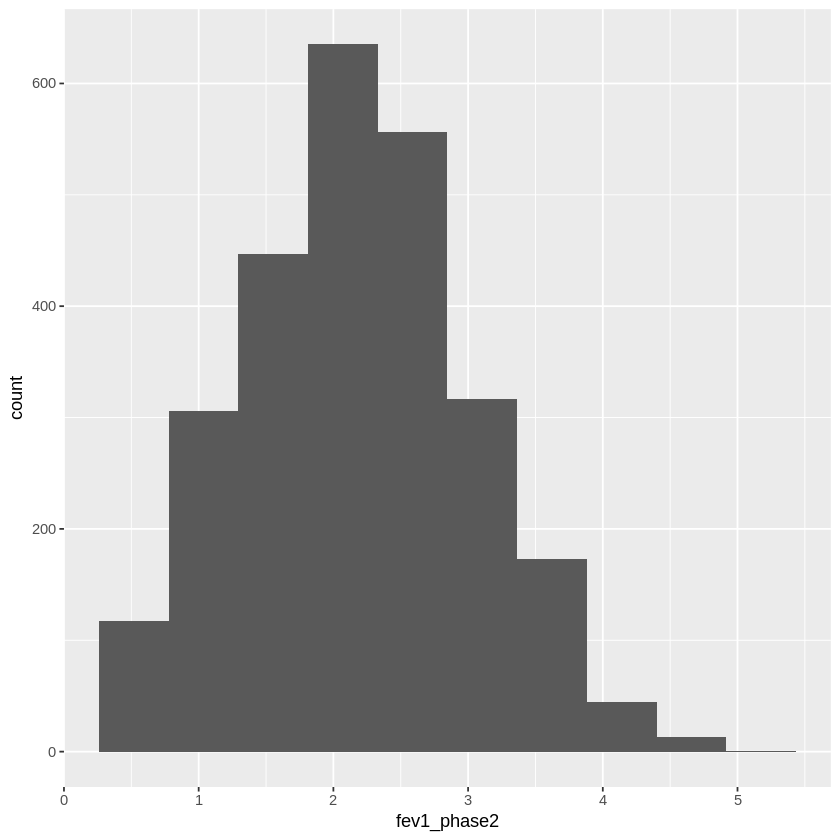

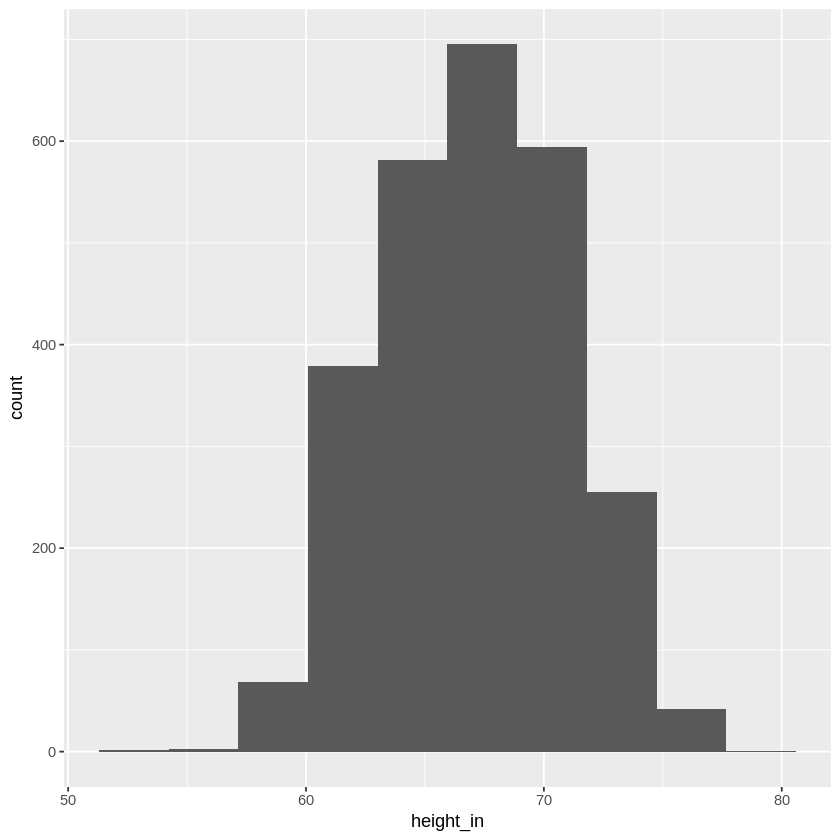

Warning message:
“Removed 2444 rows containing non-finite outside the scale range (`stat_bin()`).”


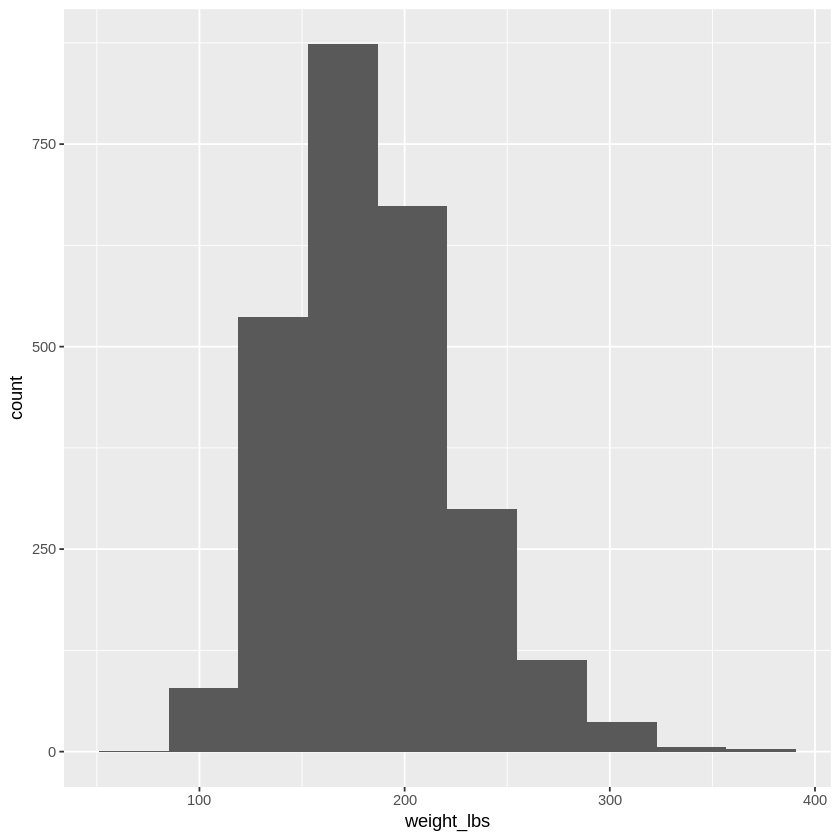

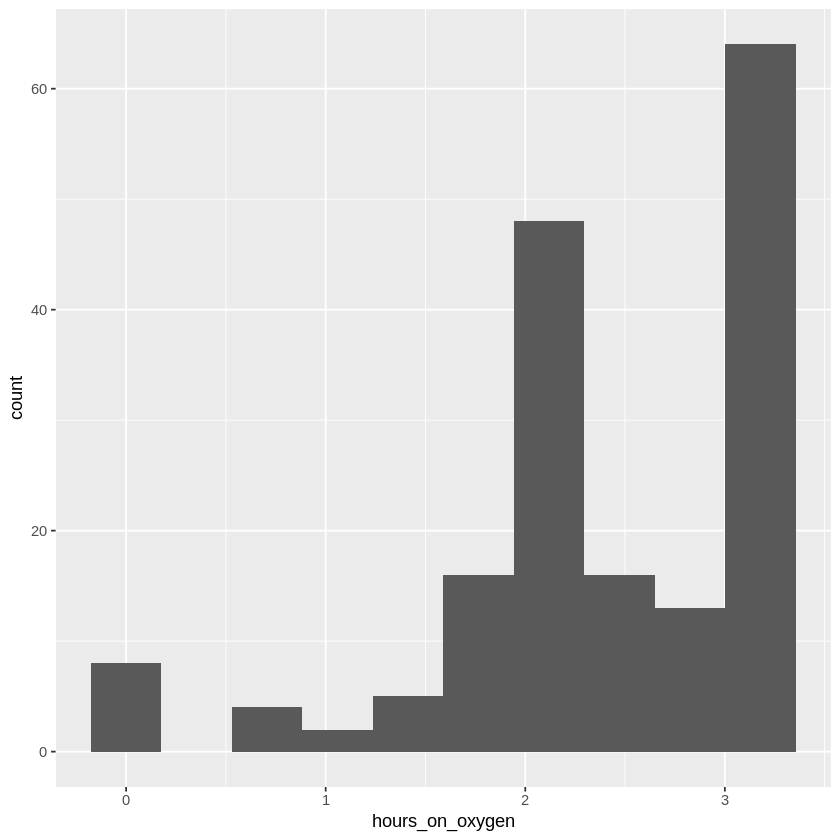

In [ ]:
#10
library(ggplot2)


for(i in 2:ncol(analysisDf)){
    if (class(analysisDf[, i]) == "numeric" || class(analysisDf[, i]) == "integer"){
      print(ggplot(data = analysisDf, aes(x = analysisDf[, i])) +
        geom_histogram(bins = 10) +
        labs(x = names(analysisDf)[i]))
  }
}

    ggplot(data = analysisDf, aes(x = log(hours_on_oxygen))) +
      geom_histogram(bins = 10) +
      labs(x = "hours_on_oxygen")


<br>

<br>

<br>

---

<br>






####<font color=red>Task 11</font>

We are primarily interested in the breathing function of the clinical trial participants after five years (`fev1_phase2`).

Using `ggplot` covered in the course,

1. Visualize the relationship between `fev1_phase2` and at least five categorical variables in your data frame

2. What are your observations? Based on your data visualizations, do there appear to be any differences in `fev1_phase2` between groups?

Warning message:
“Removed 10 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 10 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


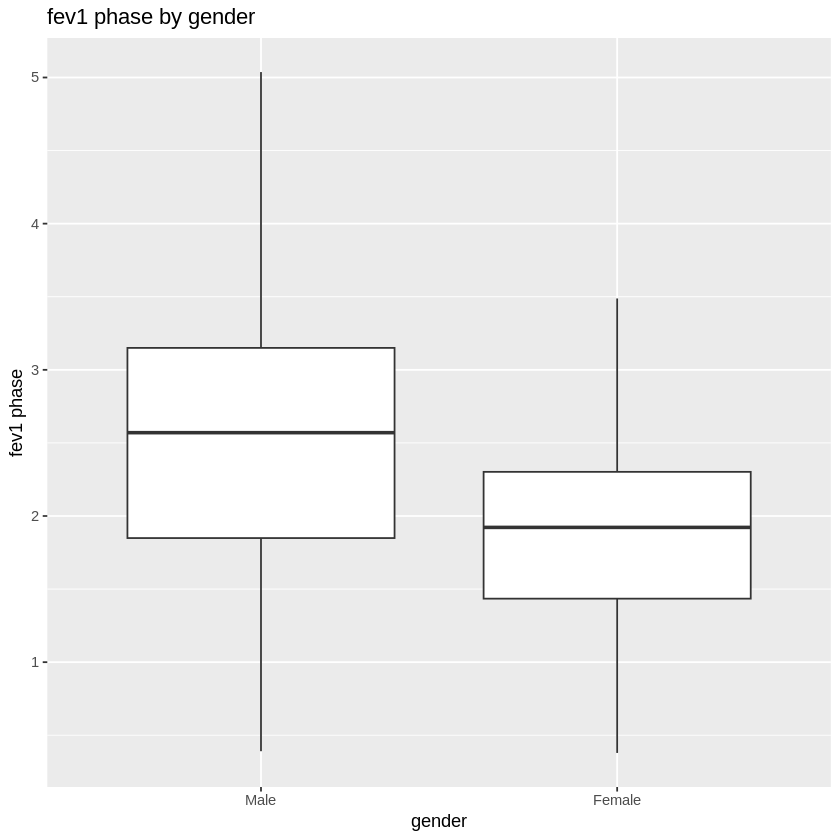

Warning message:
“Removed 10 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


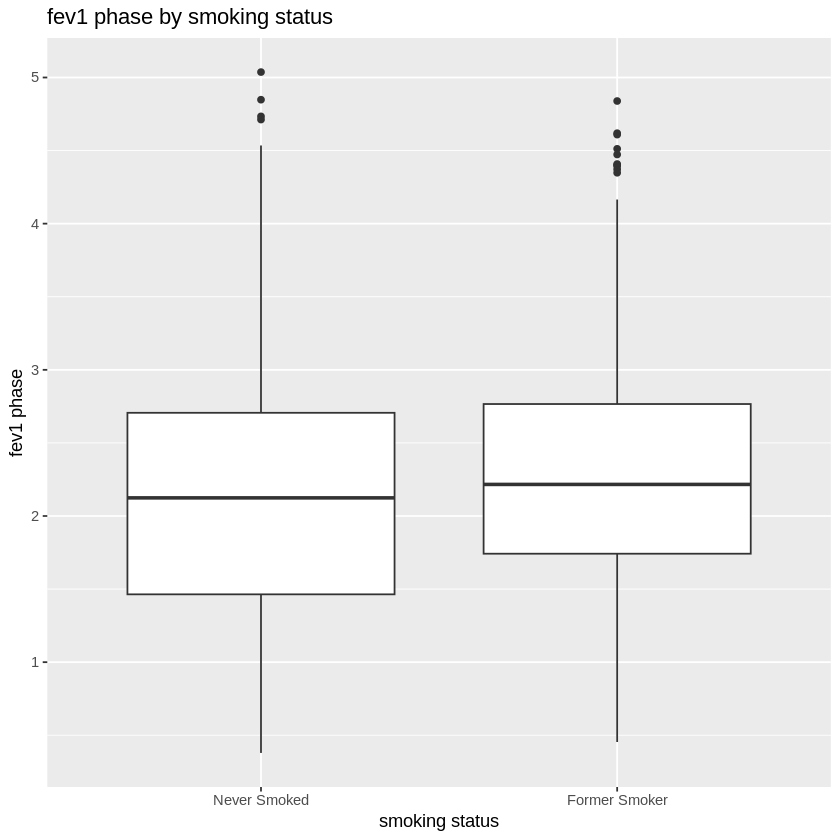

Warning message:
“Removed 10 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


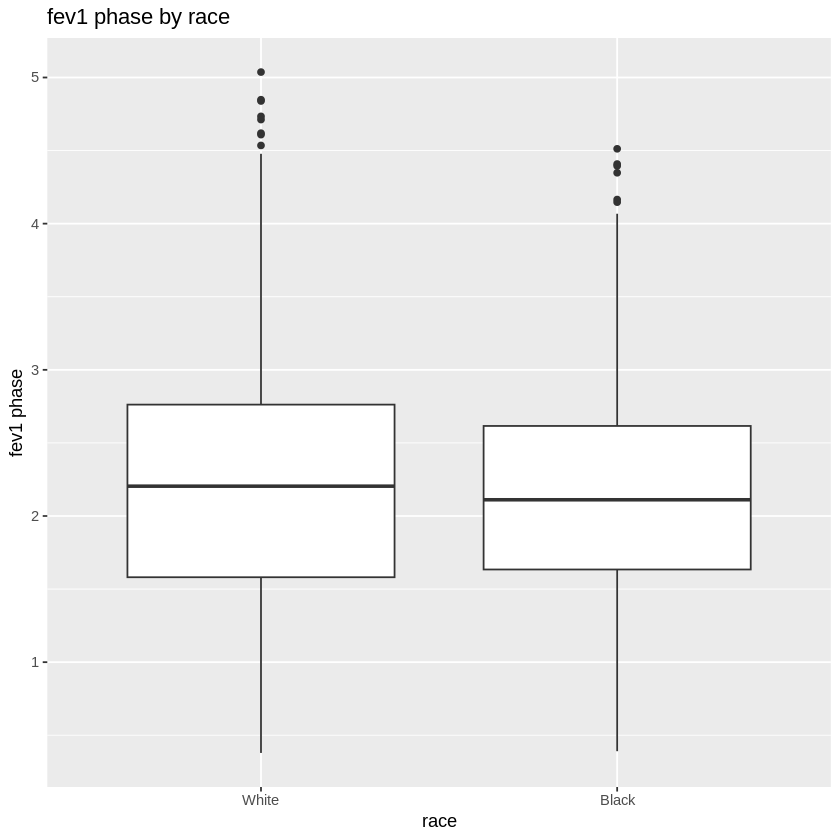

Warning message:
“Removed 10 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


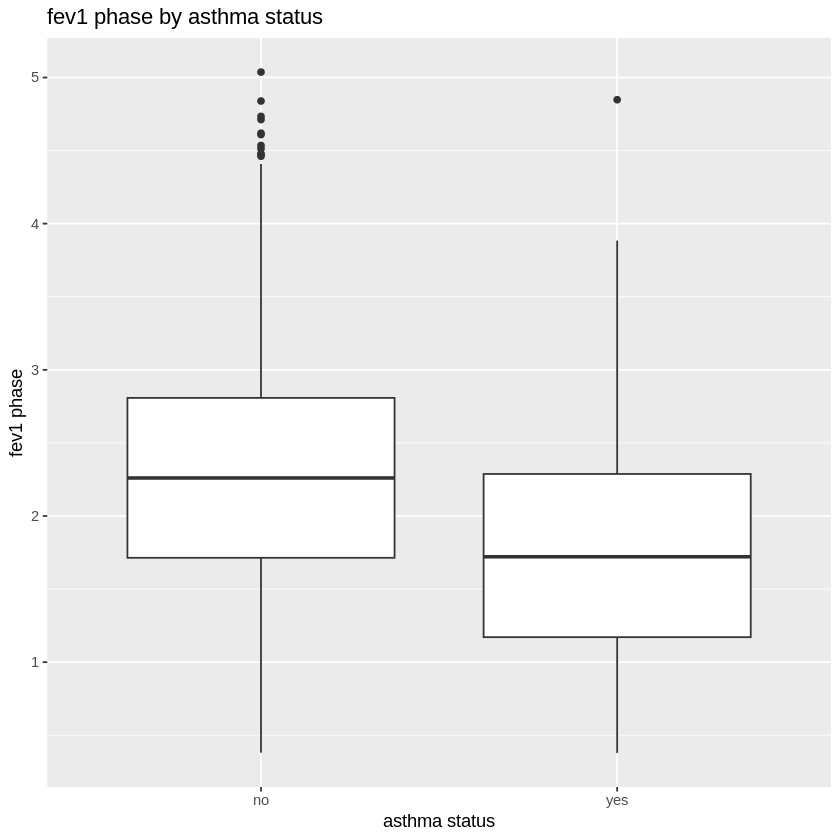

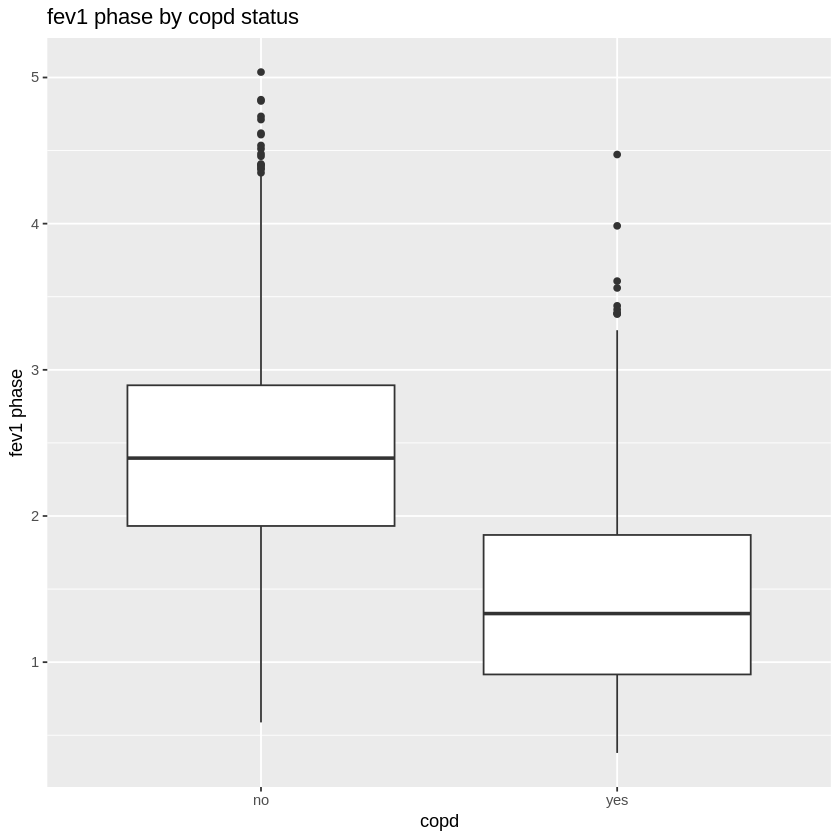

In [ ]:
#11

ggplot(analysisDf, aes(x = gender, y = finalDf$fev1_phase2)) +
  geom_boxplot() +
  labs(title = "fev1 phase by gender",
       y     = "fev1 phase",
       x     = "gender")

ggplot(analysisDf, aes(x = smoking_status, y = finalDf$fev1_phase2)) +
  geom_boxplot() +
  labs(title = "fev1 phase by smoking status",
       y     = "fev1 phase",
       x     = "smoking status")

ggplot(analysisDf, aes(x = race, y = finalDf$fev1_phase2)) +
  geom_boxplot() +
  labs(title = "fev1 phase by race",
       y     = "fev1 phase",
       x     = "race")

ggplot(analysisDf, aes(x = asthma, y = finalDf$fev1_phase2)) +
  geom_boxplot() +
  labs(title = "fev1 phase by asthma status",
       y     = "fev1 phase",
       x     = "asthma status")

ggplot(analysisDf, aes(x = copd, y = finalDf$fev1_phase2)) +
  geom_boxplot() +
  labs(title = "fev1 phase by copd status",
       y     = "fev1 phase",
       x     = "copd")

11

Race and smokings status both seemed to have very little difference in distrubution between the factors. Copd status, asthma status, and gender all seems to effect them. Women, people with asthma, and people with copd all seem to have it worse than their counterpart.

<br>

<br>

<br>

---

<br>






####<font color=red>Task 12</font>

We are primarily interested in the breathing function of the clinical trial participants after five years (`fev1_phase2`).

Using `ggplot` covered in the course,

1. Visualize the relationship between `fev1_phase2` and at least ***five*** numeric variables in your data frame

2. What are your observations? Based on your data visualizations, does there appear to be any relationships between these variables and `fev1_phase2`? Are these relationships linear? something else?

Warning message:
“Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`).”


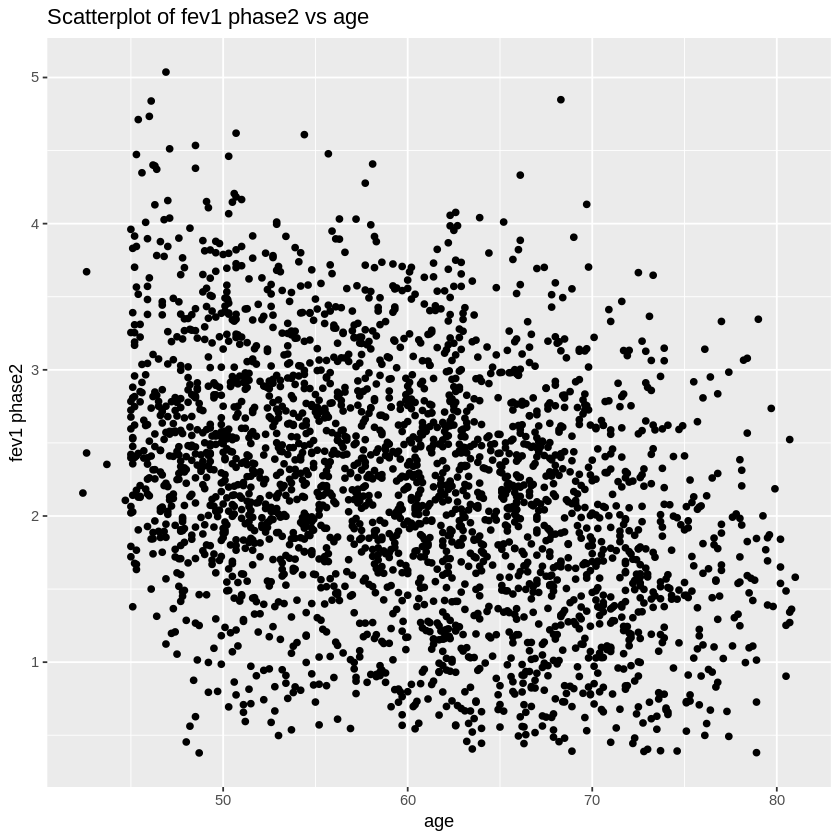

Warning message:
“Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`).”


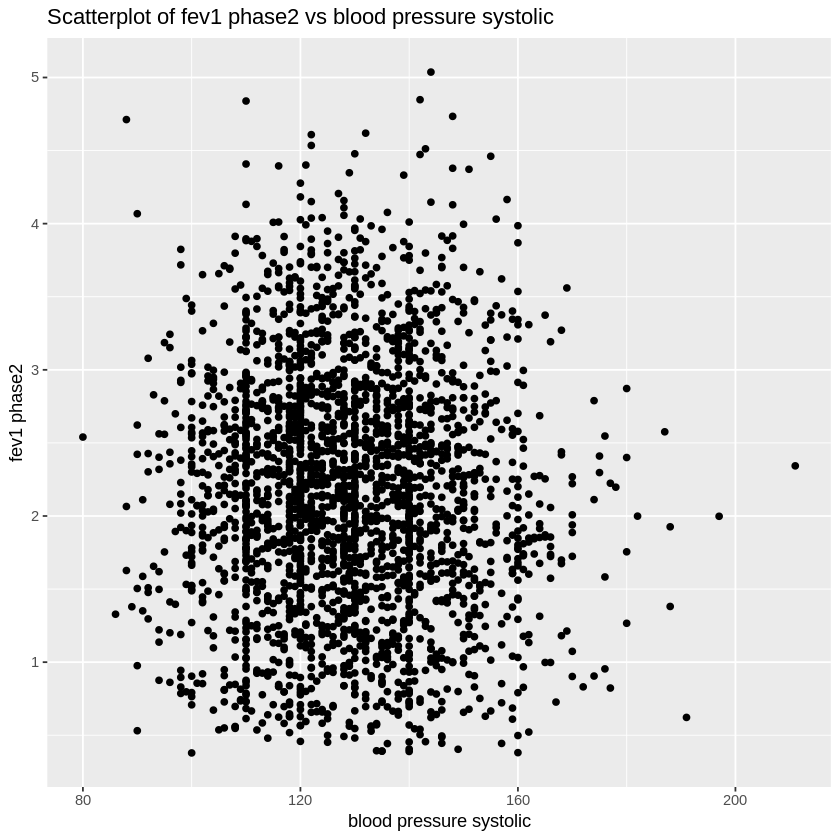

Warning message:
“Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`).”


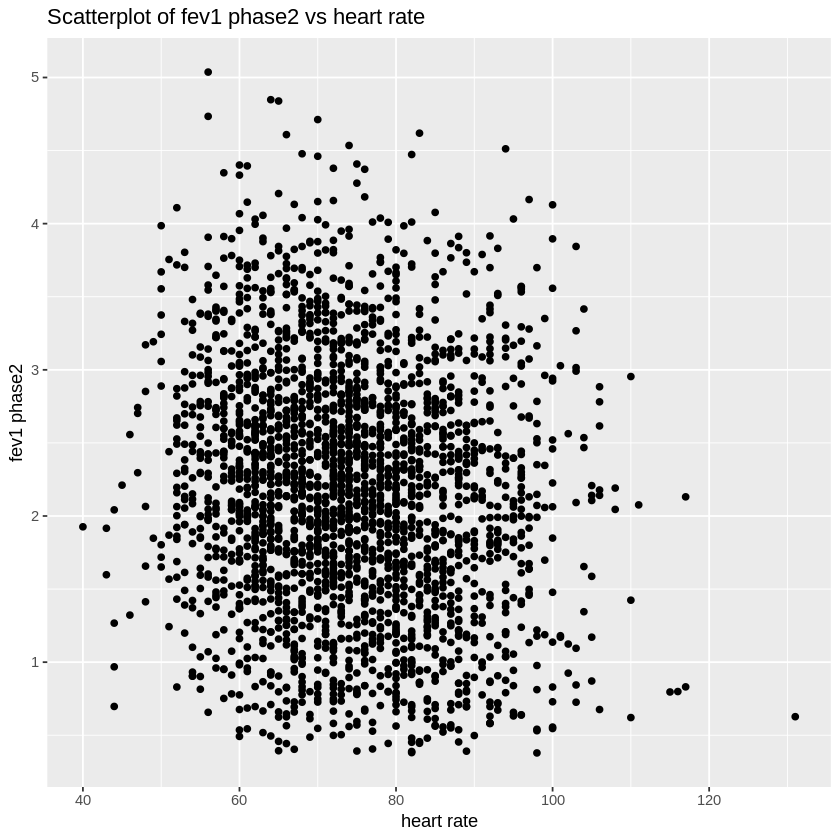

Warning message:
“Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`).”


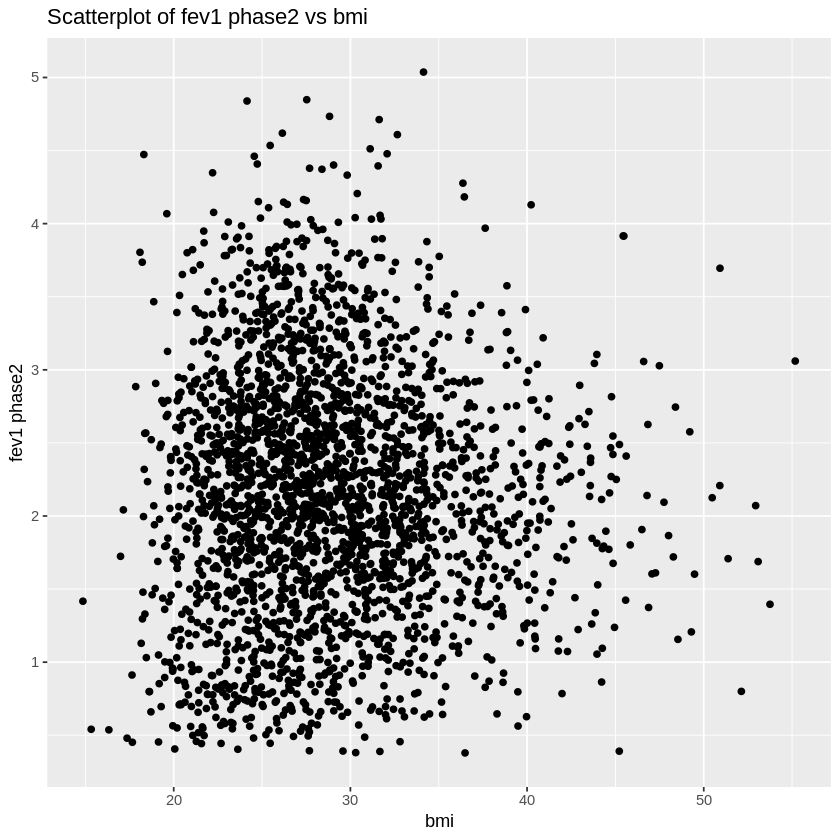

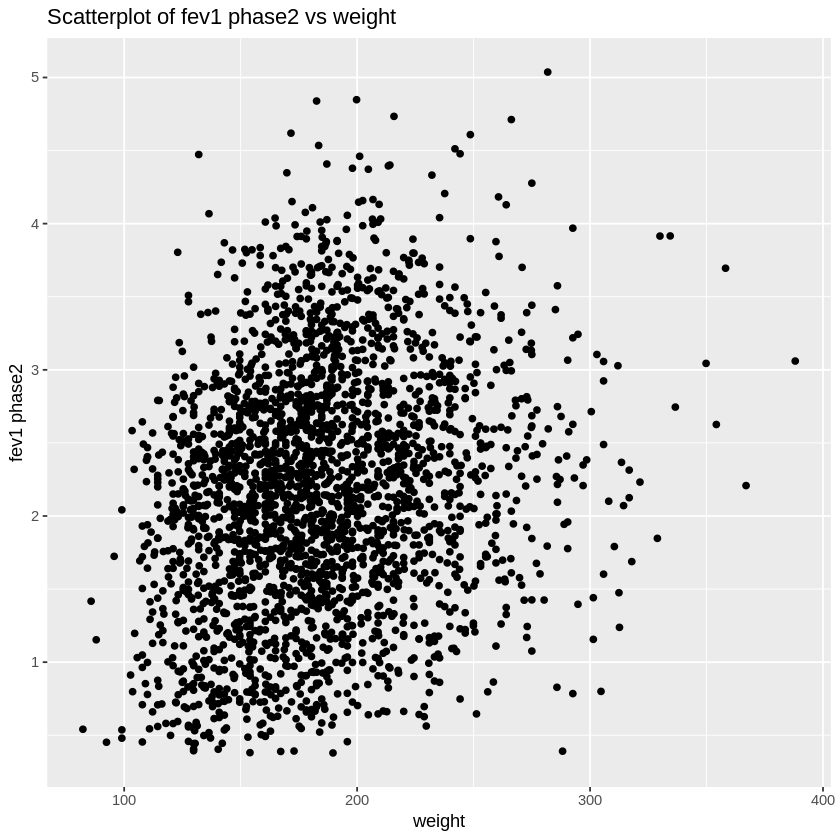

In [ ]:
#12

ggplot(analysisDf, aes(x = visit_age, y = finalDf$fev1_phase2)) +
  geom_point() +
  labs(title = "Scatterplot of fev1 phase2 vs age",
       y     = "fev1 phase2",
       x     = "age")

ggplot(analysisDf, aes(x = blood_pressure_systolic, y = finalDf$fev1_phase2)) +
  geom_point() +
  labs(title = "Scatterplot of fev1 phase2 vs blood pressure systolic",
       y     = "fev1 phase2",
       x     = "blood pressure systolic")

ggplot(analysisDf, aes(x = heart_rate, y = finalDf$fev1_phase2)) +
  geom_point() +
  labs(title = "Scatterplot of fev1 phase2 vs heart rate",
       y     = "fev1 phase2",
       x     = "heart rate")

ggplot(analysisDf, aes(x = bmi, y = finalDf$fev1_phase2)) +
  geom_point() +
  labs(title = "Scatterplot of fev1 phase2 vs bmi",
       y     = "fev1 phase2",
       x     = "bmi")

ggplot(analysisDf, aes(x = weight_lbs, y = finalDf$fev1_phase2)) +
  geom_point() +
  labs(title = "Scatterplot of fev1 phase2 vs weight",
       y     = "fev1 phase2",
       x     = "weight")


<br>

<br>

12

There appears to be a positive linear relationship with weight and bmi. A nevative linear relationship with age, and no relationship with blood presure systolic and heart rate.

---






## Inference and Modeling

####<font color=red>Task 13</font>

Using code covered in the course,

1. Conduct a statistical test to determine if there is a significant difference in `fev1_phase2` between groups from your ***five*** categorical variables in Task 11.

In [ ]:
#13

B <- 2000

n <- nrow(analysisDf)

boot_stats1 <- vector(length = B)
boot_stats2 <- vector(length = B)
boot_stats3 <- vector(length = B)
boot_stats4 <- vector(length = B)
boot_stats5 <- vector(length = B)

for(i in 1:B){
  boot_ind1      <- sample(1:nrow(analysisDf), size = n, replace = TRUE)
  boot_samp1     <- analysisDf[boot_ind1, ]

  male           <- boot_samp1[boot_samp1$gender == "Male", "fev1_phase2"]
  female         <- boot_samp1[boot_samp1$gender == "Female", "fev1_phase2"]

  boot_stat1     <- mean(male, na.rm = TRUE) - mean(female, na.rm = TRUE)

  boot_stats1[i] <- boot_stat1
}

for(i in 1:B){
  boot_ind2          <- sample(1:nrow(analysisDf), size = n, replace = TRUE)
  boot_samp2         <- analysisDf[boot_ind2, ]

  never_smoked       <- boot_samp2[boot_samp2$smoking_status == "Never Smoked", "fev1_phase2"]
  former_smoker      <- boot_samp2[boot_samp2$smoking_status == "Former Smoker", "fev1_phase2"]

  boot_stat2         <- mean(never_smoked, na.rm = TRUE) - mean(former_smoker, na.rm = TRUE)

  boot_stats2[i]     <- boot_stat2
}

for(i in 1:B){
  boot_ind3      <- sample(1:nrow(analysisDf), size = n, replace = TRUE)
  boot_samp3     <- analysisDf[boot_ind3, ]

  white          <- boot_samp3[boot_samp3$race == "White", "fev1_phase2"]
  black          <- boot_samp3[boot_samp3$race == "Black", "fev1_phase2"]

  boot_stat3     <- mean(white, na.rm = TRUE) - mean(black, na.rm = TRUE)

  boot_stats3[i] <- boot_stat3
}

for(i in 1:B){
  boot_ind4          <- sample(1:nrow(analysisDf), size = n, replace = TRUE)
  boot_samp4         <- analysisDf[boot_ind4, ]

  asthma             <- boot_samp4[boot_samp4$asthma == "yes", "fev1_phase2"]
  no_asthma          <- boot_samp4[boot_samp4$asthma == "no", "fev1_phase2"]

  boot_stat4         <- mean(asthma, na.rm = TRUE) - mean(no_asthma, na.rm = TRUE)

  boot_stats4[i]     <- boot_stat4
}

for(i in 1:B){
  boot_ind5          <- sample(1:nrow(analysisDf), size = n, replace = TRUE)
  boot_samp5         <- analysisDf[boot_ind5, ]

  copd               <- boot_samp5[boot_samp5$copd == "yes", "fev1_phase2"]
  no_copd            <- boot_samp5[boot_samp5$copd == "no", "fev1_phase2"]

  boot_stat5         <- mean(copd, na.rm = TRUE) - mean(no_copd, na.rm = TRUE)

  boot_stats5[i]     <- boot_stat5
}


print("Gender Bootstrap")
print(quantile(boot_stats1, probs = c(0.025, 0.975), na.rm = TRUE))
print("Smoking Status Bootstrap")
print(quantile(boot_stats2, probs = c(0.025, 0.975), na.rm = TRUE))
print("Race Bootstrap")
print(quantile(boot_stats3, probs = c(0.025, 0.975), na.rm = TRUE))
print("Asthma Status Bootstrap")
print(quantile(boot_stats4, probs = c(0.025, 0.975), na.rm = TRUE))
print("Copd Status Bootstrap")
print(quantile(boot_stats5, probs = c(0.025, 0.975), na.rm = TRUE))



[1] "Gender Bootstrap"
     2.5%     97.5% 
0.5628589 0.6833159 
[1] "Smoking Status Bootstrap"
       2.5%       97.5% 
-0.21215469 -0.09062315 
[1] "Race Bootstrap"
      2.5%      97.5% 
-0.0109576  0.1251170 
[1] "Asthma Status Bootstrap"
      2.5%      97.5% 
-0.5836508 -0.4276205 
[1] "Copd Status Bootstrap"
     2.5%     97.5% 
-1.038979 -0.920681 


<br>

<br>

---





####<font color=red>Task 14</font>

Using code covered in the course,

1. Fit 5 simple linear regressions using the five numeric variables from Task 12

2. Conduct a statistical test to determine if the five slopes from Task 14 are significantly different from 0

3. What are your observations/conclusions?

In [ ]:
#14

  B            <- 2000

  n            <- nrow(analysisDf)

  boot_slopes1 <- vector(length = B)
  boot_slopes2 <- vector(length = B)
  boot_slopes3 <- vector(length = B)
  boot_slopes4 <- vector(length = B)
  boot_slopes5 <- vector(length = B)

  for(i in 1:B) {
    boot_index1     <- sample(1:nrow(analysisDf), size = n, replace = TRUE)

    boot_sample1    <- analysisDf[boot_index1, ]

    boot_fit1       <- lm(formula = fev1_phase2 ~ visit_age, data = boot_sample1)

    boot_slopes1[i] <- coef(boot_fit1)[2]

  }

  for(i in 1:B) {
    boot_index2     <- sample(1:nrow(analysisDf), size = n, replace = TRUE)

    boot_sample2    <- analysisDf[boot_index2, ]

    boot_fit2       <- lm(formula = fev1_phase2 ~ blood_pressure_systolic, data = boot_sample2)

    boot_slopes2[i] <- coef(boot_fit2)[2]

  }

  for(i in 1:B) {
    boot_index3     <- sample(1:nrow(analysisDf), size = n, replace = TRUE)

    boot_sample3    <- analysisDf[boot_index3, ]

    boot_fit3       <- lm(formula = fev1_phase2 ~ heart_rate, data = boot_sample3)

    boot_slopes3[i] <- coef(boot_fit3)[2]

  }

  for(i in 1:B) {
    boot_index4     <- sample(1:nrow(analysisDf), size = n, replace = TRUE)

    boot_sample4    <- analysisDf[boot_index4, ]

    boot_fit4       <- lm(formula = fev1_phase2 ~ bmi, data = boot_sample4)

    boot_slopes4[i] <- coef(boot_fit4)[2]

  }

  for(i in 1:B) {
    boot_index5     <- sample(1:nrow(analysisDf), size = n, replace = TRUE)

    boot_sample5    <- analysisDf[boot_index5, ]

    boot_fit5       <- lm(formula = fev1_phase2 ~ weight_lbs, data = boot_sample5)

    boot_slopes5[i] <- coef(boot_fit5)[2]

  }




  print("Age vs fev1_phase2")
  print(quantile(boot_slopes1, probs = c(0.025, 0.975)))
  print("Systolic blood pressure vs fev1_phase2")
  print(quantile(boot_slopes2, probs = c(0.025, 0.975)))
  print("Heart rate vs fev1_phase2")
  print(quantile(boot_slopes3, probs = c(0.025, 0.975)))
  print("BMI vs fev1_phase2")
  print(quantile(boot_slopes4, probs = c(0.025, 0.975)))
  print("Weight vs fev1_phase2")
  print(quantile(boot_slopes5, probs = c(0.025, 0.975)))


[1] "Age vs fev1_phase2"
       2.5%       97.5% 
-0.03525539 -0.02860544 
[1] "Systolic blood pressure vs fev1_phase2"
         2.5%         97.5% 
-0.0034178986  0.0003368121 
[1] "Heart rate vs fev1_phase2"
        2.5%        97.5% 
-0.011928965 -0.006531787 
[1] "BMI vs fev1_phase2"
        2.5%        97.5% 
-0.006988589  0.003436947 
[1] "Weight vs fev1_phase2"
       2.5%       97.5% 
0.003559189 0.005085900 


14

Age, heart rate, and weight all have significant relations with fev1_phase2 while bmi and systolic blood pressure have no clear relation with fev1_phase2

<br>

<br>

---





####<font color=red>Task 15</font>

Write a 500-750 word abstract describing your analysis. Note this is a formal writeup and should be written with proper spelling and grammar. Imagine you are submitting this abstract to a conference for review. The writeup should include the following:

* Introduction to the topic of COPD and motivation for the analysis
* Description of the purpose of the study/report (what you were interested in finding)
* Briefly describe the data used to perform the analysis
* Description of the variables and methods used to conduct the analysis (data visualization, bootstrapping, regression, etc.)
* Description of the major results (estimates, significance, etc.)
* Major conclusions from the analysis in the context of the original application.



# 15

COPD stands for chronic obstructive pulmonary disease, it affects over 16 million Americans and it was of the 4 leading causes of death for Americans. It affects your respiratory system and how much you can breathe and is commonly associated with cigarette smoking. The goal of this analysis is to ascertain more information about the disease and what makes the effects of it worse or better. The research data that I am using for this analysis came from a study from copdgene.org, they conducted the largest ever study on COPD combining over 10 thousand research papers. Since the disease is commonly associated with smokers, but only a small percentage of smokers get it, they wanted to find out if some people are naturally more genetically susceptible to getting the disease than others. To find out how people are affected by it I ran an analysis mostly related to a variable called fev1_phase2. This refers to how well a patient's respiratory system is working five years after the clinical trial has ended. I used R code to visualize the distribution of other variables such as patients age, blood pressure, heart rate, bmi and other quantitative variables first. This created a baseline and let me make sure all their distributions were normal so I could have a more accurate analysis. I then directly compared the distribution of fev1_phase2 between categorical variables like gender, race, smoking status, asthma status etc. This gave me a baseline idea how the categorical variables effected fev1_phase2 before making a formal significance test. It also allowed me to actually see the data which makes it much easier to understand than purely comparing numbers. Visually what had the largest correlation with fev1_phase2 was asthma status, gender, and of course COPD status. I then make scatter plots between fev1_phase2 and quantitative variables for the same reason. Visually it appeared that blood pressure, weight, and BMI had the strongest correlation with it. Once done visualizing the samples I used bootstrapping to make 95% confidence intervals. Doing this I found that the variables which with 95% confidence have some correlation with fev1_phase2 status are Gender, smoking status, asthma status, and of course COPD status while race had no clear correlation. This shows the problem with purely visualizing data because it did not appear that smoking status had much of an effect but it did. Of course after that I did the same thing for the quantitative variables. From these confidence intervals I am 95% confident that age, heart rate,  and weight had some correlation with fev1_phase2. The major conclusions from this analysis is that things other than smoking status and COPD have some effects on fev1_phase2. Specifically gender had a major correlation. Women were much more likely to have respiratory issues and trouble breathing five years after the clinical trial. This implies that there are some genetic factors that go into susceptibility to COPD and it is not purely based on smoking, asthma, or inhaling toxins. Though as expected smoking status and asthma both still had strong correlations with COPD.

